# 00_introduction_generale

# Conception, implementation, comparaison et analyse critique de modeles de deep learning pour donnees tabulaires, images et sequences

**EMSI Casablanca - Annee universitaire 2025-2026**

Ce notebook presente un projet experimental complet en Deep Learning avec PyTorch. L'objectif est de montrer qu'une architecture neuronale doit etre adaptee a la structure des donnees :

- donnees tabulaires : perceptron multicouche (**MLP**) ;
- images : reseaux convolutionnels (**CNN**) ;
- sequences textuelles : **RNN**, **LSTM**, **GRU** et mini modele **Seq2Seq**.

Le fil conducteur du projet est le suivant : un meme paradigme d'apprentissage supervise peut etre decline tres differemment selon que les donnees sont decrites par des variables numeriques independantes, par une structure spatiale locale ou par une dependance temporelle entre tokens.

Le notebook est volontairement pedagogique : chaque partie contient la theorie minimale, l'implementation PyTorch, les experiences, les visualisations, les tableaux de resultats et une analyse critique.

## Organisation du notebook

1. `00_introduction_generale`
2. `01_import_libraries`
3. `02_configuration_reproductibilite_device`
4. `03_partie_I_MLP_donnees_tabulaires`
5. `04_partie_II_CNN_images`
6. `05_partie_III_RNN_LSTM_GRU_Seq2Seq`
7. `06_synthese_transversale_finale`
8. `07_conclusion_generale`
9. `08_requirements`

Les durees d'entrainement sont volontairement limitees pour rester compatibles avec un ordinateur etudiant. Pour obtenir des performances plus elevees, il suffit d'augmenter le nombre d'epoques.

# 01_import_libraries

Cette section regroupe les bibliotheques utilisees. Le projet evite `torchtext` dans la partie sequence afin de rester robuste : le corpus textuel est cree localement dans le notebook.

In [1]:
import math
import random
import time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

import torch
from torch import nn
from torch.utils.data import Dataset, TensorDataset, DataLoader, random_split
import torch.nn.functional as F

try:
    from torchvision import datasets, transforms
    TORCHVISION_AVAILABLE = True
except Exception as exc:
    TORCHVISION_AVAILABLE = False
    TORCHVISION_ERROR = exc

from tqdm.auto import tqdm

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# 02_configuration_reproductibilite_device

La reproductibilite est essentielle en Machine Learning experimental. On fixe donc les graines aleatoires de Python, NumPy et PyTorch. Le code utilise automatiquement le GPU si disponible.

In [2]:
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
MODEL_DIR = ROOT / "models"
FIG_DIR = ROOT / "figures"
for path in [DATA_DIR, MODEL_DIR, FIG_DIR]:
    path.mkdir(exist_ok=True)

print(f"Device utilise : {device}")
print(f"Dossier racine : {ROOT}")

Device utilise : cpu
Dossier racine : c:\Users\yahya\Desktop\DL_PROJECT


In [3]:
def count_trainable_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["train_loss"], label="train")
    axes[0].plot(history["val_loss"], label="validation")
    axes[0].set_title(f"{title} - loss")
    axes[0].set_xlabel("Epoque")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    if "val_acc" in history:
        axes[1].plot(history.get("train_acc", []), label="train")
        axes[1].plot(history["val_acc"], label="validation")
        axes[1].set_title(f"{title} - accuracy")
        axes[1].set_xlabel("Epoque")
        axes[1].set_ylabel("Accuracy")
        axes[1].legend()
    plt.tight_layout()
    plt.show()


def show_confusion_matrix(y_true, y_pred, labels, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(7, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
    plt.title(title)
    plt.xlabel("Prediction")
    plt.ylabel("Vraie classe")
    plt.show()
    return cm

# 03_partie_I_MLP_donnees_tabulaires

## Contexte et objectif

La premiere partie traite une classification binaire sur le dataset **Breast Cancer Wisconsin**. Chaque observation est decrite par des variables numeriques extraites d'images medicales, mais le modele recoit un tableau de features deja calculees. Un **MLP** est donc un choix naturel : il apprend une fonction non lineaire entre les variables d'entree et la probabilite de classe.

## Theorie essentielle : MLP et ingenierie PyTorch

Un perceptron multicouche est compose de couches lineaires suivies de fonctions d'activation. Une couche lineaire calcule `xW + b`; l'activation, par exemple ReLU, introduit de la non-linearite. Sans activation, l'empilement de couches lineaires resterait equivalent a une seule transformation lineaire.

La propagation avant produit une prediction. La fonction de perte mesure l'ecart entre prediction et cible. La retropropagation calcule les gradients de cette perte par rapport aux parametres. L'optimiseur, par exemple Adam, met ensuite les poids a jour.

Dans PyTorch, `nn.Sequential` permet de decrire une succession simple de couches. Une classe heritant de `nn.Module` offre plus de flexibilite, par exemple pour retourner des representations intermediaires ou definir plusieurs chemins de calcul. Le `state_dict` contient les tenseurs entrainables du modele ; il permet la sauvegarde, le rechargement et la reproductibilite des experiences. Le GPU accelere les operations tensorielles, mais impose que donnees et modele soient sur le meme `device`.

In [4]:
breast = load_breast_cancer()
X = breast.data
y = breast.target
feature_names = breast.feature_names
target_names = breast.target_names

print("Dimensions X :", X.shape)
print("Dimensions y :", y.shape)
print("Variables :", list(feature_names[:10]), "...")
print("Classes :", target_names)
print(pd.Series(y).value_counts().rename(index={0: target_names[0], 1: target_names[1]}))

Dimensions X : (569, 30)
Dimensions y : (569,)
Variables : [np.str_('mean radius'), np.str_('mean texture'), np.str_('mean perimeter'), np.str_('mean area'), np.str_('mean smoothness'), np.str_('mean compactness'), np.str_('mean concavity'), np.str_('mean concave points'), np.str_('mean symmetry'), np.str_('mean fractal dimension')] ...
Classes : ['malignant' 'benign']
benign       357
malignant    212
Name: count, dtype: int64


Le dataset contient 30 variables numeriques. La cible est binaire et legerement desequilibree, d'ou l'interet d'un decoupage stratifie et de metriques autres que l'accuracy.

In [5]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.20, stratify=y_train_val, random_state=SEED
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

def make_tensor_loader(X_np, y_np, batch_size=32, shuffle=False):
    X_t = torch.tensor(X_np, dtype=torch.float32)
    y_t = torch.tensor(y_np, dtype=torch.float32).view(-1, 1)
    return DataLoader(TensorDataset(X_t, y_t), batch_size=batch_size, shuffle=shuffle)

tab_train_loader = make_tensor_loader(X_train, y_train, shuffle=True)
tab_val_loader = make_tensor_loader(X_val, y_val)
tab_test_loader = make_tensor_loader(X_test, y_test)

input_dim = X_train.shape[1]
print("Train/Val/Test :", X_train.shape, X_val.shape, X_test.shape)

Train/Val/Test : (364, 30) (91, 30) (114, 30)


In [6]:
def build_mlp_sequential(input_dim, dropout=0.10):
    return nn.Sequential(
        nn.Linear(input_dim, 64),
        nn.ReLU(),
        nn.Dropout(dropout),
        nn.Linear(64, 32),
        nn.ReLU(),
        nn.Linear(32, 1),
    )


class MLPClassifier(nn.Module):
    def __init__(self, input_dim, dropout=0.10):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, 64)
        self.dropout = nn.Dropout(dropout)
        self.fc2 = nn.Linear(64, 32)
        self.out = nn.Linear(32, 1)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = F.relu(self.fc2(x))
        return self.out(x)


mlp_seq = build_mlp_sequential(input_dim).to(device)
mlp_custom = MLPClassifier(input_dim).to(device)
print(mlp_custom)
print("Parametres entrainables :", count_trainable_parameters(mlp_custom))

MLPClassifier(
  (fc1): Linear(in_features=30, out_features=64, bias=True)
  (dropout): Dropout(p=0.1, inplace=False)
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (out): Linear(in_features=32, out_features=1, bias=True)
)
Parametres entrainables : 4097


In [7]:
print("Apercu named_parameters :")
for name, param in mlp_custom.named_parameters():
    print(f"{name:15s} {tuple(param.shape)} requires_grad={param.requires_grad}")

print("\nCles du state_dict :")
print(list(mlp_custom.state_dict().keys()))

Apercu named_parameters :
fc1.weight      (64, 30) requires_grad=True
fc1.bias        (64,) requires_grad=True
fc2.weight      (32, 64) requires_grad=True
fc2.bias        (32,) requires_grad=True
out.weight      (1, 32) requires_grad=True
out.bias        (1,) requires_grad=True

Cles du state_dict :
['fc1.weight', 'fc1.bias', 'fc2.weight', 'fc2.bias', 'out.weight', 'out.bias']


Les parametres correspondent aux matrices de poids et aux biais des couches lineaires. Le `state_dict` est la representation serialisable de ces tenseurs.

In [8]:
def initialize_model(model, strategy):
    for module in model.modules():
        if isinstance(module, nn.Linear):
            if strategy == "gaussienne":
                nn.init.normal_(module.weight, mean=0.0, std=0.05)
                nn.init.zeros_(module.bias)
            elif strategy == "constante":
                nn.init.constant_(module.weight, 0.01)
                nn.init.zeros_(module.bias)
            elif strategy == "xavier":
                nn.init.xavier_uniform_(module.weight)
                nn.init.zeros_(module.bias)
            else:
                raise ValueError(strategy)
    return model


def evaluate_binary_model(model, loader, criterion):
    model.eval()
    losses, y_true, y_pred = [], [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            probs = torch.sigmoid(logits)
            preds = (probs >= 0.5).float()
            losses.append(loss.item() * xb.size(0))
            y_true.extend(yb.cpu().numpy().ravel())
            y_pred.extend(preds.cpu().numpy().ravel())
    avg_loss = np.sum(losses) / len(loader.dataset)
    acc = accuracy_score(y_true, y_pred)
    return avg_loss, acc, np.array(y_true), np.array(y_pred)


def train_binary_model(model, train_loader, val_loader, epochs=30, lr=1e-3, save_path=None):
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val = float("inf")

    for epoch in range(epochs):
        model.train()
        train_losses, train_true, train_pred = [], [], []
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            train_losses.append(loss.item() * xb.size(0))
            train_true.extend(yb.detach().cpu().numpy().ravel())
            train_pred.extend((torch.sigmoid(logits).detach().cpu().numpy().ravel() >= 0.5).astype(int))

        train_loss = np.sum(train_losses) / len(train_loader.dataset)
        train_acc = accuracy_score(train_true, train_pred)
        val_loss, val_acc, _, _ = evaluate_binary_model(model, val_loader, criterion)
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        if save_path and val_loss < best_val:
            best_val = val_loss
            torch.save(model.state_dict(), save_path)

    return history

In [9]:
init_results = []
for strategy in ["gaussienne", "constante", "xavier"]:
    set_seed()
    model = initialize_model(MLPClassifier(input_dim).to(device), strategy)
    history = train_binary_model(model, tab_train_loader, tab_val_loader, epochs=20, lr=1e-3)
    criterion = nn.BCEWithLogitsLoss()
    _, val_acc, yv, pv = evaluate_binary_model(model, tab_val_loader, criterion)
    init_results.append({
        "initialisation": strategy,
        "val_accuracy": val_acc,
        "val_f1": f1_score(yv, pv),
        "val_loss_finale": history["val_loss"][-1],
    })

pd.DataFrame(init_results).sort_values("val_f1", ascending=False)

,initialisation,val_accuracy,val_f1,val_loss_finale
0,gaussienne,0.978022,0.982456,0.075596
2,xavier,0.967033,0.973451,0.089637
1,constante,0.626374,0.770270,0.675206


Une initialisation constante est souvent moins favorable, car elle donne des neurones trop similaires au depart. Les strategies aleatoires, notamment Xavier, facilitent une propagation plus equilibree des activations et des gradients.

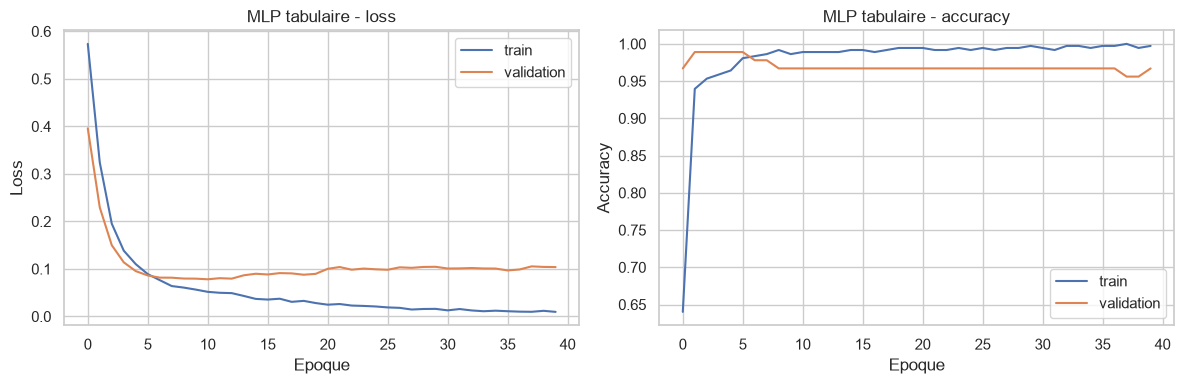

In [10]:
set_seed()
best_mlp_path = MODEL_DIR / "best_mlp_breast_cancer.pt"
best_mlp = initialize_model(MLPClassifier(input_dim).to(device), "xavier")
mlp_history = train_binary_model(best_mlp, tab_train_loader, tab_val_loader, epochs=40, lr=1e-3, save_path=best_mlp_path)
plot_history(mlp_history, "MLP tabulaire")

Les courbes permettent d'observer la convergence. Si la loss d'entrainement baisse alors que la loss validation augmente, cela signalerait un surapprentissage.

In [11]:
criterion = nn.BCEWithLogitsLoss()
best_mlp.load_state_dict(torch.load(best_mlp_path, map_location=device))
test_loss, test_acc, y_true_tab, y_pred_tab = evaluate_binary_model(best_mlp, tab_test_loader, criterion)

tab_metrics = {
    "accuracy": accuracy_score(y_true_tab, y_pred_tab),
    "precision": precision_score(y_true_tab, y_pred_tab),
    "recall": recall_score(y_true_tab, y_pred_tab),
    "f1_score": f1_score(y_true_tab, y_pred_tab),
    "test_loss": test_loss,
}
pd.DataFrame([tab_metrics])

,accuracy,precision,recall,f1_score,test_loss
0,0.95614,0.971831,0.958333,0.965035,0.094818


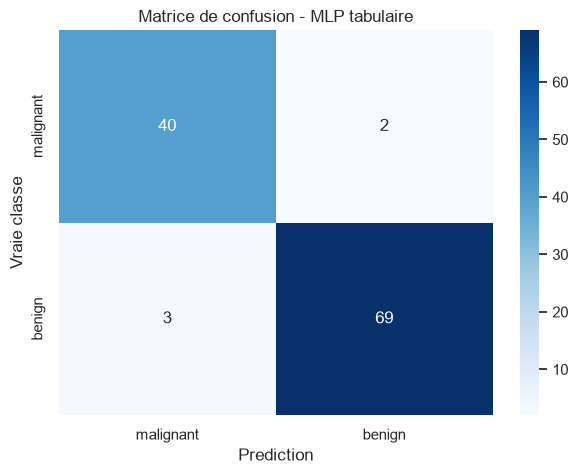

              precision    recall  f1-score   support

   malignant       0.93      0.95      0.94        42
      benign       0.97      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



In [12]:
show_confusion_matrix(y_true_tab, y_pred_tab, labels=target_names, title="Matrice de confusion - MLP tabulaire")
print(classification_report(y_true_tab, y_pred_tab, target_names=target_names))

In [13]:
reloaded_mlp = MLPClassifier(input_dim).to(device)
reloaded_mlp.load_state_dict(torch.load(best_mlp_path, map_location=device))
reload_loss, reload_acc, _, _ = evaluate_binary_model(reloaded_mlp, tab_test_loader, criterion)
print(f"Accuracy avant/apres rechargement : {test_acc:.4f} / {reload_acc:.4f}")
print(f"Loss avant/apres rechargement : {test_loss:.4f} / {reload_loss:.4f}")

Accuracy avant/apres rechargement : 0.9561 / 0.9561
Loss avant/apres rechargement : 0.0948 / 0.0948


## Analyse critique - Partie I

Un MLP bien parametre constitue une solution pertinente pour ce dataset tabulaire, car les variables sont deja des descripteurs numeriques compacts. La standardisation rend les gradients plus stables et l'architecture a deux couches cachees permet d'apprendre des interactions non lineaires entre mesures morphologiques.

Cependant, le MLP ne possede pas de biais inductif specifique aux donnees tabulaires : il ne sait pas automatiquement exploiter des relations statistiques comme le feraient parfois des arbres de decision ensemblistes. Il peut aussi etre sensible a la taille limitee du dataset, a l'initialisation, au choix du taux d'apprentissage et au surapprentissage. Les resultats doivent donc etre interpretes avec precision, rappel et F1-score, pas uniquement avec l'accuracy.

**Question de synthese.** Le MLP est efficace ici parce que la representation d'entree est deja structuree sous forme de variables descriptives. Sa limite principale est qu'il apprend cette structure uniquement a partir des donnees, sans hypothese forte sur la nature statistique des variables.

# 04_partie_II_CNN_images

## Contexte et objectif

Fashion-MNIST contient des images en niveaux de gris de taille 28 x 28 representant dix categories de vetements. Contrairement aux donnees tabulaires, une image possede une organisation spatiale : les pixels voisins sont correles. Un MLP ignore cette localite lorsqu'il aplatit l'image. Un CNN exploite au contraire la localite, le partage des poids et la hierarchie des representations.

## Theorie CNN

Une convolution applique un noyau local sur l'image pour produire une carte de caracteristiques. Le partage des poids reduit le nombre de parametres et permet de detecter un meme motif a plusieurs positions. Le padding controle la conservation de la taille spatiale. Le stride controle le pas de deplacement du filtre. Le pooling reduit la resolution et augmente une forme de robustesse aux petites translations. Une convolution 1x1 melange les canaux sans regarder un voisinage spatial plus large.

La taille de sortie apres convolution est :

`H_out = floor((H + 2P - K) / S) + 1`

Pour une image 28 x 28, un noyau 5 x 5, padding 0, stride 1 donne `24 x 24`. Avec padding 2, on obtient `28 x 28`.

In [14]:
def conv_output_size(H, K, P=0, S=1):
    return math.floor((H + 2 * P - K) / S) + 1

print("28x28, kernel=5, padding=0, stride=1 ->", conv_output_size(28, 5, 0, 1))
print("28x28, kernel=5, padding=2, stride=1 ->", conv_output_size(28, 5, 2, 1))
print("28x28, kernel=5, padding=0, stride=2 ->", conv_output_size(28, 5, 0, 2))

28x28, kernel=5, padding=0, stride=1 -> 24
28x28, kernel=5, padding=2, stride=1 -> 28
28x28, kernel=5, padding=0, stride=2 -> 12


In [15]:
def corr2d(X, K):
    h, w = K.shape
    Y = torch.zeros((X.shape[0] - h + 1, X.shape[1] - w + 1))
    for i in range(Y.shape[0]):
        for j in range(Y.shape[1]):
            Y[i, j] = (X[i:i+h, j:j+w] * K).sum()
    return Y


def max_pool2d_simple(X, pool_size):
    ph, pw = pool_size
    Y = torch.zeros((X.shape[0] // ph, X.shape[1] // pw))
    for i in range(Y.shape[0]):
        for j in range(Y.shape[1]):
            Y[i, j] = X[i*ph:(i+1)*ph, j*pw:(j+1)*pw].max()
    return Y


def avg_pool2d_simple(X, pool_size):
    ph, pw = pool_size
    Y = torch.zeros((X.shape[0] // ph, X.shape[1] // pw))
    for i in range(Y.shape[0]):
        for j in range(Y.shape[1]):
            Y[i, j] = X[i*ph:(i+1)*ph, j*pw:(j+1)*pw].mean()
    return Y


X_demo = torch.arange(16, dtype=torch.float32).reshape(4, 4)
K_demo = torch.tensor([[1., -1.], [0., 2.]])
print("Correlation manuelle :\n", corr2d(X_demo, K_demo))
conv = nn.Conv2d(1, 1, kernel_size=2, bias=False)
conv.weight.data = K_demo.reshape(1, 1, 2, 2)
print("Conv2d PyTorch :\n", conv(X_demo.reshape(1, 1, 4, 4)).squeeze())
print("MaxPool manuel :\n", max_pool2d_simple(X_demo, (2, 2)))
print("AvgPool manuel :\n", avg_pool2d_simple(X_demo, (2, 2)))

Correlation manuelle :
 tensor([[ 9., 11., 13.],
        [17., 19., 21.],
        [25., 27., 29.]])
Conv2d PyTorch :
 tensor([[ 9., 11., 13.],
        [17., 19., 21.],
        [25., 27., 29.]], grad_fn=<SqueezeBackward0>)
MaxPool manuel :
 tensor([[ 5.,  7.],
        [13., 15.]])
AvgPool manuel :
 tensor([[ 2.5000,  4.5000],
        [10.5000, 12.5000]])


Ces fonctions montrent explicitement les operations effectuees par les couches PyTorch. En pratique, les modules optimises de PyTorch sont preferables pour l'entrainement.

In [16]:
if not TORCHVISION_AVAILABLE:
    raise RuntimeError(f"torchvision indisponible : {TORCHVISION_ERROR}")

transform = transforms.ToTensor()
full_train = datasets.FashionMNIST(root=DATA_DIR, train=True, download=True, transform=transform)
test_dataset = datasets.FashionMNIST(root=DATA_DIR, train=False, download=True, transform=transform)

# Sous-ensemble volontairement limite pour un temps d'execution raisonnable.
train_subset_size = 12000
val_subset_size = 3000
remaining = len(full_train) - train_subset_size - val_subset_size
train_dataset, val_dataset, _ = random_split(
    full_train,
    [train_subset_size, val_subset_size, remaining],
    generator=torch.Generator().manual_seed(SEED),
)

img_train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, num_workers=0)
img_val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False, num_workers=0)
img_test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False, num_workers=0)

classes_fmnist = full_train.classes
print(classes_fmnist)

100%|██████████| 26.4M/26.4M [00:19<00:00, 1.36MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 92.8kB/s]
100%|██████████| 4.42M/4.42M [00:02<00:00, 1.80MB/s]
100%|██████████| 5.15k/5.15k [00:00<?, ?B/s]

['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


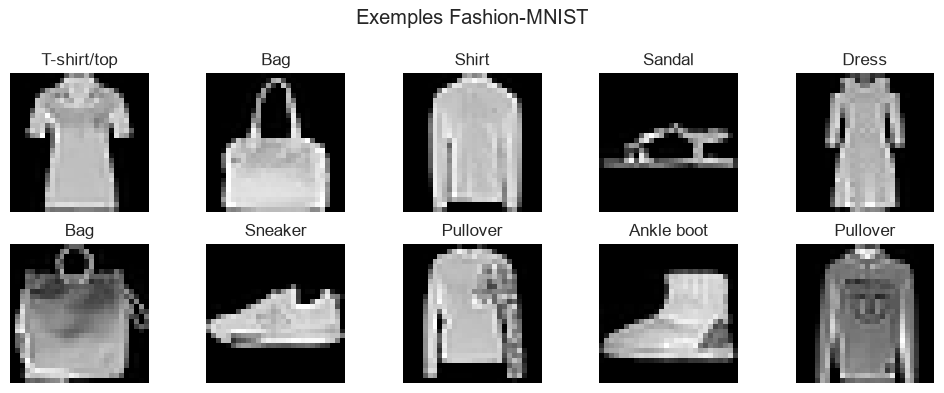

Ankle boot     1193
Bag            1151
Coat           1240
Dress          1172
Pullover       1253
Sandal         1261
Shirt          1195
Sneaker        1212
T-shirt/top    1159
Trouser        1164
Name: count, dtype: int64

In [17]:
images, labels = next(iter(img_train_loader))
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, img, label in zip(axes.ravel(), images[:10], labels[:10]):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(classes_fmnist[label])
    ax.axis("off")
plt.suptitle("Exemples Fashion-MNIST")
plt.tight_layout()
plt.show()

train_labels = [full_train.targets[i].item() for i in train_dataset.indices]
pd.Series(train_labels).map(dict(enumerate(classes_fmnist))).value_counts().sort_index()

Les exemples illustrent une variabilite intra-classe importante. Les classes visuellement proches, comme shirt, coat et pullover, seront souvent les plus difficiles a separer.

In [18]:
class ImageMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.net(x)


class LeNetLikeCNN(nn.Module):
    def __init__(self, padding=0, pooling="max", filters=(6, 16), use_1x1=False, stride=1):
        super().__init__()
        pool_cls = nn.MaxPool2d if pooling == "max" else nn.AvgPool2d
        layers = [
            nn.Conv2d(1, filters[0], kernel_size=5, padding=padding, stride=stride),
            nn.ReLU(),
            pool_cls(2),
        ]
        if use_1x1:
            layers += [nn.Conv2d(filters[0], filters[0], kernel_size=1), nn.ReLU()]
        layers += [
            nn.Conv2d(filters[0], filters[1], kernel_size=5),
            nn.ReLU(),
            pool_cls(2),
        ]
        self.features = nn.Sequential(*layers)
        with torch.no_grad():
            dummy = torch.zeros(1, 1, 28, 28)
            n_flat = self.features(dummy).numel()
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(n_flat, 120),
            nn.ReLU(),
            nn.Linear(120, 84),
            nn.ReLU(),
            nn.Linear(84, 10),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

In [19]:
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * xb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        total += xb.size(0)
    return total_loss / total, correct / total


def evaluate_multiclass(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    y_true, y_pred = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            total_loss += loss.item() * xb.size(0)
            pred = logits.argmax(1)
            correct += (pred == yb).sum().item()
            total += xb.size(0)
            y_true.extend(yb.cpu().numpy())
            y_pred.extend(pred.cpu().numpy())
    return total_loss / total, correct / total, np.array(y_true), np.array(y_pred)


def fit_model(model, train_loader, val_loader, epochs=3, lr=1e-3):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    start = time.time()
    for _ in tqdm(range(epochs), desc="Entrainement"):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, criterion)
        val_loss, val_acc, _, _ = evaluate_multiclass(model, val_loader, criterion)
        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
    elapsed = time.time() - start
    return history, elapsed

Entrainement:   0%|          | 0/3 [00:00<?, ?it/s]

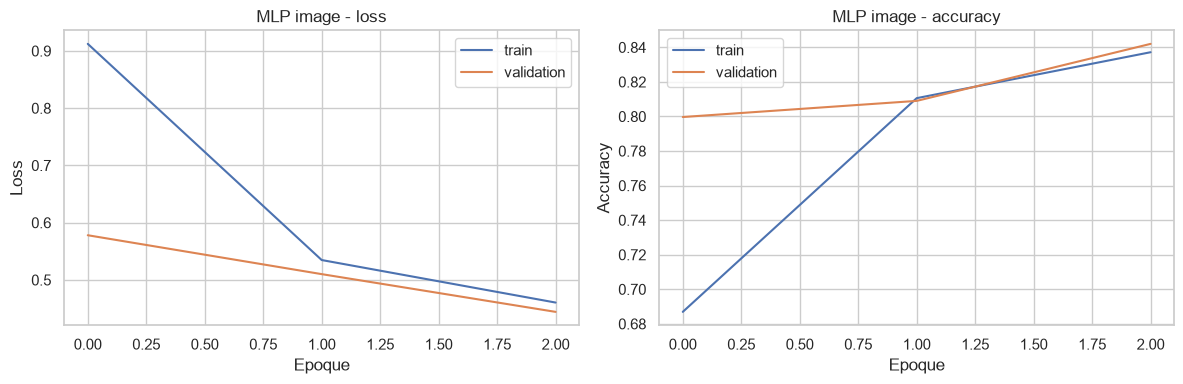

Entrainement:   0%|          | 0/3 [00:00<?, ?it/s]

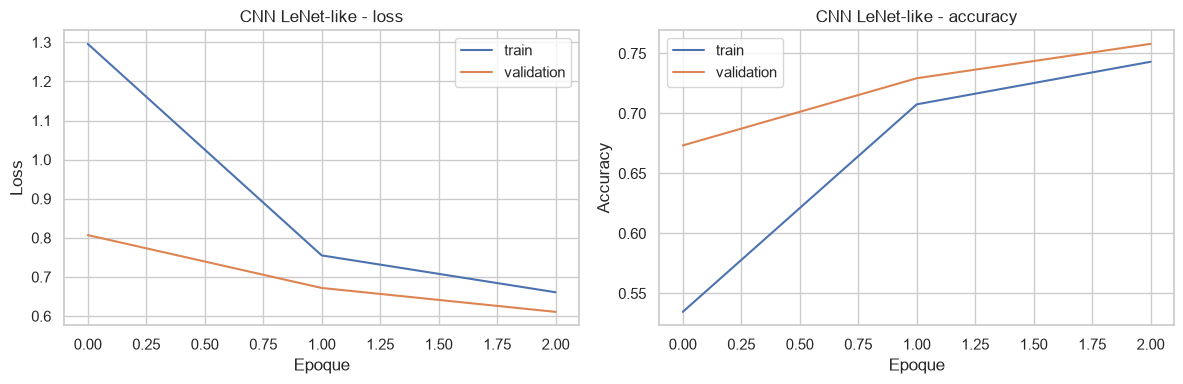

,modele,test_accuracy,test_f1_macro,temps_s,parametres
0,MLP image,0.8300,0.830723,5.425813,235146
1,CNN LeNet-like,0.7591,0.744842,7.650840,44426


In [20]:
image_results = []

for name, model in [("MLP image", ImageMLP()), ("CNN LeNet-like", LeNetLikeCNN())]:
    set_seed()
    model = model.to(device)
    history, elapsed = fit_model(model, img_train_loader, img_val_loader, epochs=3, lr=1e-3)
    plot_history(history, name)
    criterion = nn.CrossEntropyLoss()
    test_loss, test_acc, yt, yp = evaluate_multiclass(model, img_test_loader, criterion)
    image_results.append({
        "modele": name,
        "test_accuracy": test_acc,
        "test_f1_macro": f1_score(yt, yp, average="macro"),
        "temps_s": elapsed,
        "parametres": count_trainable_parameters(model),
        "model_obj": model,
        "y_true": yt,
        "y_pred": yp,
    })

pd.DataFrame([{k: v for k, v in r.items() if k not in ["model_obj", "y_true", "y_pred"]} for r in image_results])

La comparaison MLP/CNN met en evidence l'interet du biais inductif convolutionnel : le CNN exploite les voisinages locaux et partage ses filtres sur toute l'image.

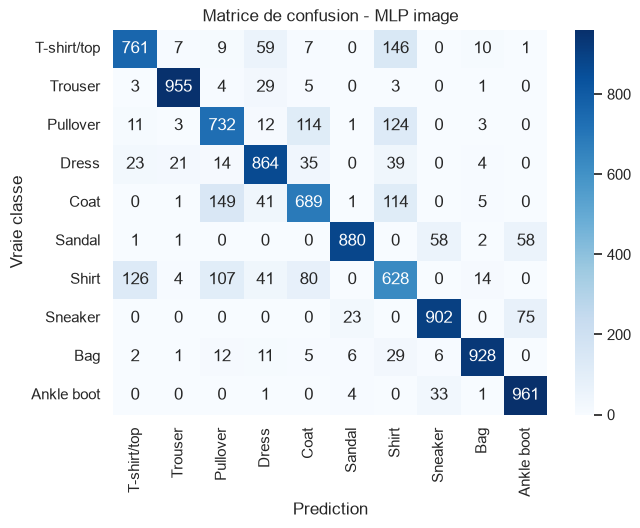

              precision    recall  f1-score   support

 T-shirt/top       0.82      0.76      0.79      1000
     Trouser       0.96      0.95      0.96      1000
    Pullover       0.71      0.73      0.72      1000
       Dress       0.82      0.86      0.84      1000
        Coat       0.74      0.69      0.71      1000
      Sandal       0.96      0.88      0.92      1000
       Shirt       0.58      0.63      0.60      1000
     Sneaker       0.90      0.90      0.90      1000
         Bag       0.96      0.93      0.94      1000
  Ankle boot       0.88      0.96      0.92      1000

    accuracy                           0.83     10000
   macro avg       0.83      0.83      0.83     10000
weighted avg       0.83      0.83      0.83     10000



In [21]:
best_image = max(image_results, key=lambda r: r["test_f1_macro"])
show_confusion_matrix(best_image["y_true"], best_image["y_pred"], labels=classes_fmnist, title=f"Matrice de confusion - {best_image['modele']}")
print(classification_report(best_image["y_true"], best_image["y_pred"], target_names=classes_fmnist))

In [22]:
variant_configs = [
    {"nom": "padding0_stride1_max", "padding": 0, "stride": 1, "pooling": "max", "filters": (6, 16), "use_1x1": False},
    {"nom": "padding2_stride1_max", "padding": 2, "stride": 1, "pooling": "max", "filters": (6, 16), "use_1x1": False},
    {"nom": "padding0_stride2_max", "padding": 0, "stride": 2, "pooling": "max", "filters": (6, 16), "use_1x1": False},
    {"nom": "padding0_stride1_avg", "padding": 0, "stride": 1, "pooling": "avg", "filters": (6, 16), "use_1x1": False},
    {"nom": "filtres_plus_nombreux", "padding": 0, "stride": 1, "pooling": "max", "filters": (12, 32), "use_1x1": False},
    {"nom": "avec_conv_1x1", "padding": 0, "stride": 1, "pooling": "max", "filters": (6, 16), "use_1x1": True},
]

variant_rows = []
for cfg in variant_configs:
    set_seed()
    model = LeNetLikeCNN(
        padding=cfg["padding"],
        pooling=cfg["pooling"],
        filters=cfg["filters"],
        use_1x1=cfg["use_1x1"],
        stride=cfg["stride"],
    ).to(device)
    history, elapsed = fit_model(model, img_train_loader, img_val_loader, epochs=1, lr=1e-3)
    criterion = nn.CrossEntropyLoss()
    val_loss, val_acc, yt, yp = evaluate_multiclass(model, img_val_loader, criterion)
    variant_rows.append({
        "variante": cfg["nom"],
        "val_accuracy": val_acc,
        "val_f1_macro": f1_score(yt, yp, average="macro"),
        "parametres": count_trainable_parameters(model),
        "temps_s": elapsed,
    })

pd.DataFrame(variant_rows).sort_values("val_f1_macro", ascending=False)

Entrainement:   0%|          | 0/1 [00:00<?, ?it/s]

Entrainement:   0%|          | 0/1 [00:00<?, ?it/s]

Entrainement:   0%|          | 0/1 [00:00<?, ?it/s]

Entrainement:   0%|          | 0/1 [00:00<?, ?it/s]

Entrainement:   0%|          | 0/1 [00:00<?, ?it/s]

Entrainement:   0%|          | 0/1 [00:00<?, ?it/s]

,variante,val_accuracy,val_f1_macro,parametres,temps_s
1,padding2_stride1_max,0.675000,0.653261,61706,5.495648
5,avec_conv_1x1,0.656667,0.648270,44468,3.486975
4,filtres_plus_nombreux,0.665667,0.645830,82518,4.212636
3,padding0_stride1_avg,0.667667,0.637469,44426,3.358349
2,padding0_stride2_max,0.645667,0.624862,15626,2.763824
0,padding0_stride1_max,0.631667,0.605636,44426,3.779598


Ces variantes isolent des choix architecturaux. Le padding conserve davantage d'information aux bords, le stride reduit rapidement la resolution, le pooling moyen lisse les activations, et l'augmentation du nombre de filtres augmente la capacite au prix d'un cout de calcul plus eleve.

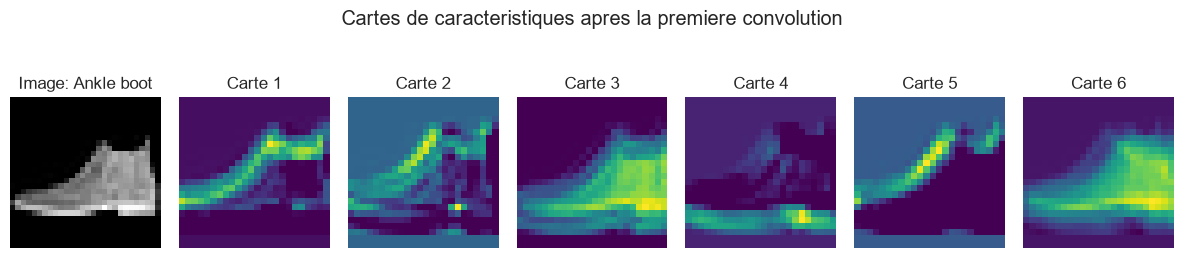

In [23]:
cnn_model = next(r["model_obj"] for r in image_results if r["modele"] == "CNN LeNet-like")
cnn_model.eval()
sample_img, sample_label = test_dataset[0]
with torch.no_grad():
    maps = cnn_model.features[:2](sample_img.unsqueeze(0).to(device)).cpu().squeeze(0)

n_maps = min(6, maps.shape[0])
fig, axes = plt.subplots(1, n_maps + 1, figsize=(12, 3))
axes[0].imshow(sample_img.squeeze(), cmap="gray")
axes[0].set_title(f"Image: {classes_fmnist[sample_label]}")
axes[0].axis("off")
for i in range(n_maps):
    axes[i + 1].imshow(maps[i], cmap="viridis")
    axes[i + 1].set_title(f"Carte {i+1}")
    axes[i + 1].axis("off")
plt.suptitle("Cartes de caracteristiques apres la premiere convolution")
plt.tight_layout()
plt.show()

Les premieres cartes de caracteristiques reagissent souvent a des contrastes simples : bords, zones sombres, zones claires et motifs locaux. Elles ne representent pas encore des concepts semantiques complets, mais des briques visuelles reutilisables.

## Analyse critique - Partie II

Un CNN est plus pertinent qu'un MLP pour les images car il respecte la geometrie 2D des donnees. Les filtres locaux apprennent des motifs partageables sur toute l'image, alors qu'un MLP traite chaque pixel aplati comme une variable independante. Les choix de padding, stride et pooling influencent directement la quantite d'information conservee, la taille des cartes et le cout de calcul. Une profondeur plus grande permet des representations plus abstraites, mais augmente le risque de surapprentissage et le temps d'entrainement.

**Question de synthese.** Le CNN gagne en pertinence car son architecture incorpore des hypotheses compatibles avec les images : localite, invariance partielle et composition hierarchique.

# 05_partie_III_RNN_LSTM_GRU_Seq2Seq

## Contexte et objectif

Cette partie construit un mini-corpus textuel local afin de demontrer tout le pipeline sequence : tokenisation, vocabulaire, padding, mini-lots, modeles recurrents, gradient clipping, modele de langage, Seq2Seq, greedy decoding et beam search simplifie.

## Theorie des sequences

Une sequence est une suite ordonnee d'elements. Pour le texte, les tokens successifs dependent du contexte precedent. Un MLP classique a entree fixe ne capture pas naturellement cette temporalite. Un modele de langage factorise la probabilite d'une phrase avec la regle de chaine :

`P(x1, x2, ..., xT) = produit_t P(xt | x1, ..., x(t-1))`

La perplexite est `exp(loss moyenne)` lorsque la loss est une entropie croisee. Plus elle est basse, plus le modele attribue une forte probabilite aux tokens observes. Les RNN sont entraines par BPTT, mais peuvent souffrir de gradients qui disparaissent ou explosent. Le gradient clipping limite la norme des gradients. LSTM et GRU ameliorent la memoire grace a des portes. Le schema encodeur-decodeur transforme une sequence source en representation interne, puis genere une sequence cible avec teacher forcing pendant l'entrainement.

In [24]:
parallel_corpus = [
    ("je suis etudiant", "i am a student"),
    ("je suis fatigue", "i am tired"),
    ("je suis heureux", "i am happy"),
    ("il est professeur", "he is a teacher"),
    ("elle est intelligente", "she is smart"),
    ("nous aimons le deep learning", "we like deep learning"),
    ("vous aimez pytorch", "you like pytorch"),
    ("ils regardent une image", "they look at an image"),
    ("elle lit un livre", "she reads a book"),
    ("nous etudions les reseaux", "we study networks"),
    ("le modele apprend", "the model learns"),
    ("la loss diminue", "the loss decreases"),
    ("le gradient est stable", "the gradient is stable"),
    ("je code un reseau", "i code a network"),
    ("pytorch utilise des tenseurs", "pytorch uses tensors"),
    ("le cnn analyse une image", "the cnn analyzes an image"),
    ("le rnn lit une sequence", "the rnn reads a sequence"),
    ("le gru est rapide", "the gru is fast"),
    ("le lstm garde la memoire", "the lstm keeps memory"),
    ("nous comparons les modeles", "we compare the models"),
]

SPECIALS = ["<pad>", "<sos>", "<eos>", "<unk>"]
PAD, SOS, EOS, UNK = SPECIALS

def tokenize(text):
    return text.lower().strip().split()


def build_vocab(sentences, min_freq=1):
    counter = Counter()
    for sent in sentences:
        counter.update(tokenize(sent))
    vocab = SPECIALS + sorted([tok for tok, freq in counter.items() if freq >= min_freq])
    stoi = {tok: i for i, tok in enumerate(vocab)}
    itos = {i: tok for tok, i in stoi.items()}
    return stoi, itos


src_stoi, src_itos = build_vocab([src for src, _ in parallel_corpus])
tgt_stoi, tgt_itos = build_vocab([tgt for _, tgt in parallel_corpus])

def encode(sentence, stoi, add_sos=False, add_eos=True):
    ids = [stoi.get(tok, stoi[UNK]) for tok in tokenize(sentence)]
    if add_sos:
        ids = [stoi[SOS]] + ids
    if add_eos:
        ids = ids + [stoi[EOS]]
    return ids

print("Taille vocab source :", len(src_stoi))
print("Taille vocab cible :", len(tgt_stoi))

Taille vocab source : 55
Taille vocab cible : 52


In [25]:
class ParallelTextDataset(Dataset):
    def __init__(self, pairs):
        self.pairs = pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        src, tgt = self.pairs[idx]
        return (
            torch.tensor(encode(src, src_stoi), dtype=torch.long),
            torch.tensor(encode(tgt, tgt_stoi, add_sos=True), dtype=torch.long),
        )


def pad_collate(batch):
    src_batch, tgt_batch = zip(*batch)
    src_pad = nn.utils.rnn.pad_sequence(src_batch, batch_first=True, padding_value=src_stoi[PAD])
    tgt_pad = nn.utils.rnn.pad_sequence(tgt_batch, batch_first=True, padding_value=tgt_stoi[PAD])
    return src_pad, tgt_pad


text_loader = DataLoader(ParallelTextDataset(parallel_corpus), batch_size=4, shuffle=True, collate_fn=pad_collate)
src_batch, tgt_batch = next(iter(text_loader))
print(src_batch.shape, tgt_batch.shape)

torch.Size([4, 6]) torch.Size([4, 7])


In [26]:
lm_sentences = [src for src, _ in parallel_corpus] + [tgt for _, tgt in parallel_corpus]
lm_stoi, lm_itos = build_vocab(lm_sentences)

class LanguageModelDataset(Dataset):
    def __init__(self, sentences):
        self.samples = [torch.tensor(encode(s, lm_stoi, add_sos=True), dtype=torch.long) for s in sentences]

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        seq = self.samples[idx]
        return seq[:-1], seq[1:]


def lm_collate(batch):
    xs, ys = zip(*batch)
    xpad = nn.utils.rnn.pad_sequence(xs, batch_first=True, padding_value=lm_stoi[PAD])
    ypad = nn.utils.rnn.pad_sequence(ys, batch_first=True, padding_value=lm_stoi[PAD])
    return xpad, ypad


lm_loader = DataLoader(LanguageModelDataset(lm_sentences), batch_size=8, shuffle=True, collate_fn=lm_collate)

In [27]:
class RecurrentLanguageModel(nn.Module):
    def __init__(self, vocab_size, rnn_type="RNN", emb_dim=32, hidden_dim=64):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=lm_stoi[PAD])
        rnn_cls = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[rnn_type]
        self.rnn = rnn_cls(emb_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x):
        emb = self.embedding(x)
        out, _ = self.rnn(emb)
        return self.fc(out)


def train_language_model(model, loader, epochs=60, lr=0.01, clip=None):
    criterion = nn.CrossEntropyLoss(ignore_index=lm_stoi[PAD])
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    losses, grad_norms = [], []
    start = time.time()
    for _ in range(epochs):
        model.train()
        total_loss, total_tokens = 0.0, 0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits.reshape(-1, logits.size(-1)), yb.reshape(-1))
            loss.backward()
            total_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), clip) if clip else torch.norm(torch.stack([
                p.grad.detach().norm() for p in model.parameters() if p.grad is not None
            ]))
            optimizer.step()
            mask = yb != lm_stoi[PAD]
            total_loss += loss.item() * mask.sum().item()
            total_tokens += mask.sum().item()
            grad_norms.append(float(total_norm))
        losses.append(total_loss / total_tokens)
    return {"loss": losses, "grad_norms": grad_norms, "time_s": time.time() - start}


def generate_lm(model, prefix, max_len=8):
    model.eval()
    ids = [lm_stoi[SOS]] + [lm_stoi.get(tok, lm_stoi[UNK]) for tok in tokenize(prefix)]
    for _ in range(max_len):
        x = torch.tensor(ids, dtype=torch.long, device=device).unsqueeze(0)
        with torch.no_grad():
            next_id = model(x)[0, -1].argmax().item()
        if next_id == lm_stoi[EOS]:
            break
        ids.append(next_id)
    return " ".join(lm_itos[i] for i in ids[1:] if i not in [lm_stoi[PAD], lm_stoi[EOS]])

In [28]:
lm_results = []
lm_histories = {}
for rnn_type in ["RNN", "LSTM", "GRU"]:
    set_seed()
    model = RecurrentLanguageModel(len(lm_stoi), rnn_type=rnn_type).to(device)
    hist = train_language_model(model, lm_loader, epochs=60, lr=0.01, clip=1.0)
    final_loss = hist["loss"][-1]
    lm_results.append({
        "modele": rnn_type,
        "loss_finale": final_loss,
        "perplexite": math.exp(final_loss),
        "temps_s": hist["time_s"],
        "phrase_generee": generate_lm(model, "le"),
    })
    lm_histories[rnn_type] = hist

pd.DataFrame(lm_results)

,modele,loss_finale,perplexite,temps_s,phrase_generee
0,RNN,0.811399,2.251056,0.962635,le modele apprend
1,LSTM,0.801544,2.228979,1.100684,le modele apprend
2,GRU,0.809697,2.247226,1.532094,le gradient est stable


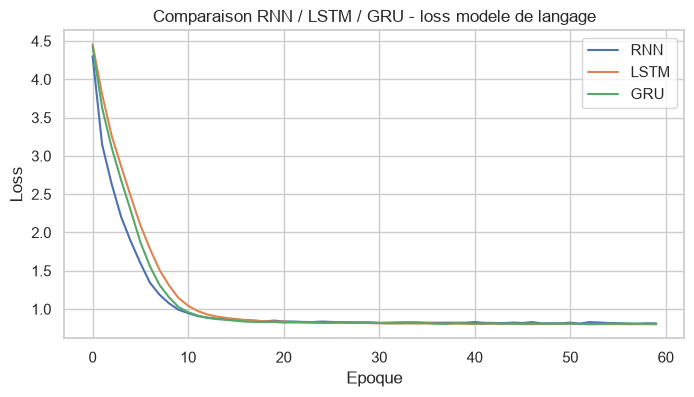

In [29]:
plt.figure(figsize=(8, 4))
for name, hist in lm_histories.items():
    plt.plot(hist["loss"], label=name)
plt.title("Comparaison RNN / LSTM / GRU - loss modele de langage")
plt.xlabel("Epoque")
plt.ylabel("Loss")
plt.legend()
plt.show()

Sur un mini-corpus, les trois modeles peuvent memoriser une partie des regularites. LSTM et GRU sont conceptuellement plus robustes pour des dependances longues, mais le corpus est trop petit pour conclure statistiquement.

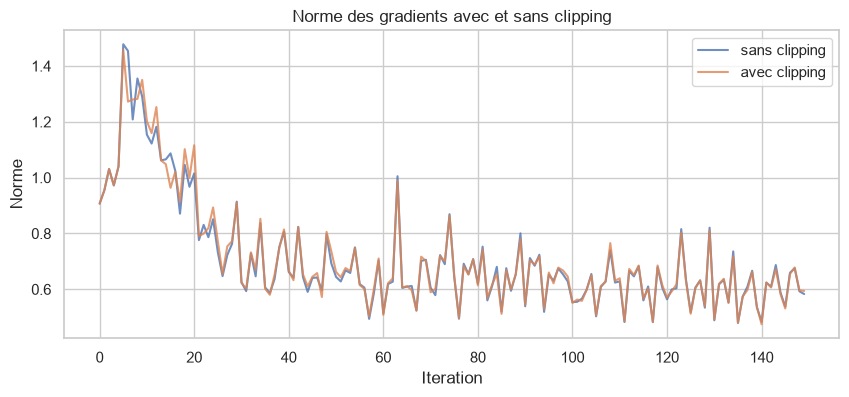

In [30]:
set_seed()
lm_no_clip = RecurrentLanguageModel(len(lm_stoi), rnn_type="RNN").to(device)
hist_no_clip = train_language_model(lm_no_clip, lm_loader, epochs=30, lr=0.02, clip=None)

set_seed()
lm_clip = RecurrentLanguageModel(len(lm_stoi), rnn_type="RNN").to(device)
hist_clip = train_language_model(lm_clip, lm_loader, epochs=30, lr=0.02, clip=1.0)

plt.figure(figsize=(10, 4))
plt.plot(hist_no_clip["grad_norms"], label="sans clipping", alpha=0.8)
plt.plot(hist_clip["grad_norms"], label="avec clipping", alpha=0.8)
plt.title("Norme des gradients avec et sans clipping")
plt.xlabel("Iteration")
plt.ylabel("Norme")
plt.legend()
plt.show()

Le clipping est une mesure pratique contre les gradients explosifs. Il ne resout pas tous les problemes d'optimisation, mais limite les mises a jour excessives.

In [31]:
class EncoderRNN(nn.Module):
    def __init__(self, input_dim, emb_dim=32, hidden_dim=64, rnn_type="GRU"):
        super().__init__()
        self.embedding = nn.Embedding(input_dim, emb_dim, padding_idx=src_stoi[PAD])
        rnn_cls = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[rnn_type]
        self.rnn_type = rnn_type
        self.rnn = rnn_cls(emb_dim, hidden_dim, batch_first=True)

    def forward(self, src):
        embedded = self.embedding(src)
        outputs, hidden = self.rnn(embedded)
        return hidden


class DecoderRNN(nn.Module):
    def __init__(self, output_dim, emb_dim=32, hidden_dim=64, rnn_type="GRU"):
        super().__init__()
        self.embedding = nn.Embedding(output_dim, emb_dim, padding_idx=tgt_stoi[PAD])
        rnn_cls = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[rnn_type]
        self.rnn = rnn_cls(emb_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, input_token, hidden):
        embedded = self.embedding(input_token.unsqueeze(1))
        output, hidden = self.rnn(embedded, hidden)
        prediction = self.fc(output.squeeze(1))
        return prediction, hidden


class Seq2Seq(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder

    def forward(self, src, tgt, teacher_forcing_ratio=0.5):
        batch_size, tgt_len = tgt.shape
        vocab_size = self.decoder.fc.out_features
        outputs = torch.zeros(batch_size, tgt_len, vocab_size, device=src.device)
        hidden = self.encoder(src)
        input_token = tgt[:, 0]
        for t in range(1, tgt_len):
            logits, hidden = self.decoder(input_token, hidden)
            outputs[:, t] = logits
            teacher_force = random.random() < teacher_forcing_ratio
            input_token = tgt[:, t] if teacher_force else logits.argmax(1)
        return outputs

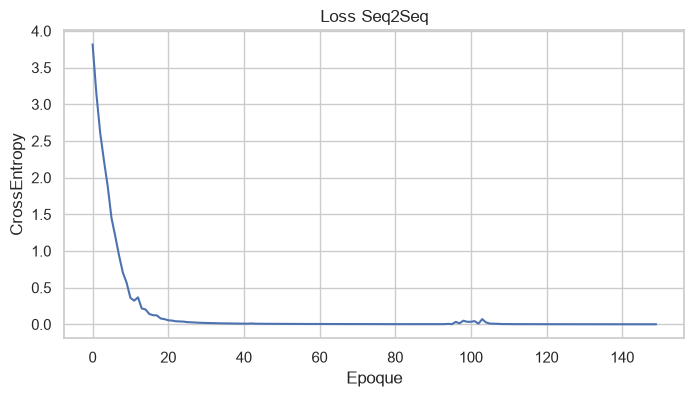

Perplexite finale approx. : 1.0011613170813216


In [32]:
def train_seq2seq(model, loader, epochs=150, lr=0.01):
    criterion = nn.CrossEntropyLoss(ignore_index=tgt_stoi[PAD])
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    losses = []
    for _ in range(epochs):
        model.train()
        total_loss, total_tokens = 0.0, 0
        for src, tgt in loader:
            src, tgt = src.to(device), tgt.to(device)
            optimizer.zero_grad()
            outputs = model(src, tgt, teacher_forcing_ratio=0.6)
            loss = criterion(outputs[:, 1:].reshape(-1, outputs.size(-1)), tgt[:, 1:].reshape(-1))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            mask = tgt[:, 1:] != tgt_stoi[PAD]
            total_loss += loss.item() * mask.sum().item()
            total_tokens += mask.sum().item()
        losses.append(total_loss / total_tokens)
    return losses


set_seed()
seq2seq = Seq2Seq(
    EncoderRNN(len(src_stoi), rnn_type="GRU"),
    DecoderRNN(len(tgt_stoi), rnn_type="GRU"),
).to(device)
seq_losses = train_seq2seq(seq2seq, text_loader, epochs=150, lr=0.01)

plt.figure(figsize=(8, 4))
plt.plot(seq_losses)
plt.title("Loss Seq2Seq")
plt.xlabel("Epoque")
plt.ylabel("CrossEntropy")
plt.show()
print("Perplexite finale approx. :", math.exp(seq_losses[-1]))

In [33]:
def ids_to_sentence(ids, itos, stop_eos=True):
    toks = []
    for idx in ids:
        tok = itos[int(idx)]
        if stop_eos and tok == EOS:
            break
        if tok not in SPECIALS:
            toks.append(tok)
    return " ".join(toks)


def greedy_decode(model, src_sentence, max_len=10):
    model.eval()
    src_ids = torch.tensor(encode(src_sentence, src_stoi), dtype=torch.long, device=device).unsqueeze(0)
    hidden = model.encoder(src_ids)
    input_token = torch.tensor([tgt_stoi[SOS]], device=device)
    output_ids = []
    with torch.no_grad():
        for _ in range(max_len):
            logits, hidden = model.decoder(input_token, hidden)
            next_id = logits.argmax(1).item()
            if next_id == tgt_stoi[EOS]:
                break
            output_ids.append(next_id)
            input_token = torch.tensor([next_id], device=device)
    return ids_to_sentence(output_ids, tgt_itos, stop_eos=False)


def beam_search_decode(model, src_sentence, beam_width=3, max_len=10):
    model.eval()
    src_ids = torch.tensor(encode(src_sentence, src_stoi), dtype=torch.long, device=device).unsqueeze(0)
    hidden0 = model.encoder(src_ids)
    beams = [([tgt_stoi[SOS]], 0.0, hidden0)]
    with torch.no_grad():
        for _ in range(max_len):
            candidates = []
            for seq, score, hidden in beams:
                if seq[-1] == tgt_stoi[EOS]:
                    candidates.append((seq, score, hidden))
                    continue
                input_token = torch.tensor([seq[-1]], device=device)
                logits, new_hidden = model.decoder(input_token, hidden)
                log_probs = F.log_softmax(logits, dim=-1).squeeze(0)
                topv, topi = torch.topk(log_probs, beam_width)
                for v, i in zip(topv.tolist(), topi.tolist()):
                    candidates.append((seq + [i], score + v, new_hidden))
            beams = sorted(candidates, key=lambda x: x[1] / len(x[0]), reverse=True)[:beam_width]
            if all(seq[-1] == tgt_stoi[EOS] for seq, _, _ in beams):
                break
    best_seq = beams[0][0][1:]
    return ids_to_sentence(best_seq, tgt_itos)


translation_rows = []
for src, tgt in parallel_corpus[:8]:
    translation_rows.append({
        "source": src,
        "cible": tgt,
        "greedy": greedy_decode(seq2seq, src),
        "beam_search": beam_search_decode(seq2seq, src),
    })
pd.DataFrame(translation_rows)

,source,cible,greedy,beam_search
0,je suis etudiant,i am a student,i am a student,i am a student
1,je suis fatigue,i am tired,i am tired,i am tired
2,je suis heureux,i am happy,i am happy,i am happy
3,il est professeur,he is a teacher,he is a teacher,he is a teacher
4,elle est intelligente,she is smart,she is smart,she is smart
5,nous aimons le deep learning,we like deep learning,we like deep learning,we like deep learning
6,vous aimez pytorch,you like pytorch,you like pytorch,you like pytorch
7,ils regardent une image,they look at an image,they look at an image,they look at an image


In [34]:
def unigram_bleu(reference, candidate):
    ref = tokenize(reference)
    cand = tokenize(candidate)
    if not cand:
        return 0.0
    ref_counts = Counter(ref)
    cand_counts = Counter(cand)
    clipped = sum(min(count, ref_counts[token]) for token, count in cand_counts.items())
    precision = clipped / len(cand)
    bp = 1.0 if len(cand) >= len(ref) else math.exp(1 - len(ref) / max(len(cand), 1))
    return bp * precision


bleu_rows = []
for src, tgt in parallel_corpus:
    pred = beam_search_decode(seq2seq, src)
    bleu_rows.append({"source": src, "cible": tgt, "prediction": pred, "bleu_unigram": unigram_bleu(tgt, pred)})
pd.DataFrame(bleu_rows).head(10)

,source,cible,prediction,bleu_unigram
0,je suis etudiant,i am a student,i am a student,1.0
1,je suis fatigue,i am tired,i am tired,1.0
2,je suis heureux,i am happy,i am happy,1.0
3,il est professeur,he is a teacher,he is a teacher,1.0
4,elle est intelligente,she is smart,she is smart,1.0
5,nous aimons le deep learning,we like deep learning,we like deep learning,1.0
6,vous aimez pytorch,you like pytorch,you like pytorch,1.0
7,ils regardent une image,they look at an image,they look at an image,1.0
8,elle lit un livre,she reads a book,she reads a book,1.0
9,nous etudions les reseaux,we study networks,we study networks,1.0


Le BLEU unigrame simplifie mesure le recouvrement lexical entre prediction et reference. Sur un corpus aussi petit, cette metrique reste indicative : elle ne remplace pas une evaluation robuste sur un vrai jeu de test.

In [35]:
comparison_seq = pd.DataFrame(lm_results)
comparison_seq["stabilite"] = ["moyenne", "bonne", "bonne"]
comparison_seq["memoire"] = ["faible", "forte", "intermediaire"]
comparison_seq["commentaire"] = [
    "Simple mais sensible aux dependances longues.",
    "Plus robuste grace aux portes et a la cellule memoire.",
    "Bon compromis entre cout et capacite memoire.",
]
comparison_seq

,modele,loss_finale,perplexite,temps_s,phrase_generee,stabilite,memoire,commentaire
0,RNN,0.811399,2.251056,0.962635,le modele apprend,moyenne,faible,Simple mais sensible aux dependances longues.
1,LSTM,0.801544,2.228979,1.100684,le modele apprend,bonne,forte,Plus robuste grace aux portes et a la cellule ...
2,GRU,0.809697,2.247226,1.532094,le gradient est stable,bonne,intermediaire,Bon compromis entre cout et capacite memoire.


## Analyse critique - Partie III

Les architectures recurrentes permettent de modeliser une sequence en reutilisant un etat cache au fil du temps. Le RNN simple illustre le principe, mais il devient fragile lorsque les dependances s'allongent. LSTM et GRU introduisent des portes qui regulent l'oubli, l'ecriture et la lecture de l'information, ce qui stabilise l'apprentissage. Le passage au Seq2Seq devient pertinent lorsque l'entree et la sortie sont deux sequences de longueurs potentiellement differentes, comme en traduction.

Le teacher forcing accelere l'entrainement mais cree un decalage avec l'inference, ou le modele doit consommer ses propres predictions. Le greedy decoding est rapide mais myope ; le beam search explore plusieurs hypotheses et peut ameliorer la qualite au prix d'un cout superieur. Sur ce mini-corpus, les resultats montrent surtout la comprehension du pipeline ; ils ne doivent pas etre confondus avec une performance de traduction industrielle.

**Question de synthese.** Le passage RNN -> LSTM/GRU -> Seq2Seq se justifie par l'augmentation progressive du besoin de memoire, de stabilite et de flexibilite entre sequence source et sequence cible.

# 06_synthese_transversale_finale

Le deep learning adapte ses architectures a la structure des donnees. Pour les donnees tabulaires, le MLP apprend des interactions non lineaires entre variables numeriques. Il convient lorsque chaque observation est deja representee par un vecteur de features. Sa faiblesse est l'absence de biais inductif fort pour les distributions tabulaires complexes.

Pour les images, le CNN est plus adapte car il exploite la geometrie spatiale : voisinages locaux, partage des filtres, cartes de caracteristiques et hierarchie de motifs. Les choix de padding, stride, pooling et profondeur modifient directement la resolution, la capacite et le cout de calcul.

Pour les sequences, les modeles recurrents tiennent compte de l'ordre. Un RNN simple encode la dependance temporelle, mais LSTM et GRU gerent mieux la memoire et la stabilite des gradients. Le Seq2Seq generalise cette idee pour transformer une sequence en une autre, avec decodage glouton ou beam search.

La comparaison globale montre qu'un meme objectif supervise ne suffit pas a definir le bon modele. La geometrie des donnees, la dependance locale, la temporalite et la representation initiale imposent des architectures differentes. Le choix d'un modele n'est donc pas seulement une question de performance, mais aussi de compatibilite entre les hypotheses internes du reseau et la structure du probleme.

| Type de donnees | Architecture | Biais inductif principal | Limite principale |
|---|---|---|---|
| Tabulaire | MLP | Interactions non lineaires entre variables | Peu de structure explicite |
| Image | CNN | Localite et partage des poids | Sensible aux choix architecturaux |
| Sequence | RNN/LSTM/GRU | Ordre temporel et memoire | Dependances longues difficiles |
| Sequence vers sequence | Seq2Seq | Encodage puis generation | Evaluation fragile sur petit corpus |

# 07_conclusion_generale

Ce projet montre que l'efficacite du deep learning depend fortement de l'adequation entre les donnees et l'architecture. Le MLP est une base solide pour les donnees tabulaires standardisees. Le CNN devient superieur pour les images car il exploite la structure spatiale. Les RNN, LSTM et GRU introduisent une memoire temporelle necessaire aux sequences, tandis que le Seq2Seq permet de passer d'une sequence source a une sequence cible.

Les resultats experimentaux doivent etre lus avec prudence : les datasets sont volontairement simples, les durees d'entrainement limitees et le corpus textuel pedagogique. Cette contrainte est cependant coherente avec l'objectif du module : comprendre, implementer, comparer et analyser.

## Plan de rapport scientifique propose

1. Introduction
2. Objectifs du projet
3. Partie I : MLP pour donnees tabulaires
   - theorie
   - methodologie
   - implementation
   - resultats
   - analyse critique
4. Partie II : CNN pour images
   - theorie
   - calculs manuels
   - implementation
   - comparaison MLP/CNN
   - resultats
   - analyse critique
5. Partie III : RNN/LSTM/GRU/Seq2Seq
   - theorie
   - preparation textuelle
   - modeles
   - resultats
   - analyse critique
6. Synthese transversale
7. Limites generales
8. Conclusion
9. References
10. Annexes experimentales

# 08_requirements

Le fichier `requirements.txt` associe au projet contient :

```txt
numpy
pandas
matplotlib
seaborn
scikit-learn
torch
torchvision
torchtext
tqdm
jupyter
nbformat
```

La partie sequence du notebook fonctionne sans `torchtext`, ce qui evite les problemes frequents de compatibilite entre versions de PyTorch et torchtext.